# Basic IO positions at expiration

## 0. Scope

Replication diagnostic of Natenberg, *Option Volatility and Pricing*, chapter 4: expiration P&L of basic positions. This is not a strategy or profitability claim. The book supplies the payoff formulas; contracts and indicative premiums are market examples, not book parameters.

## 1. Data flow

```text
JOSEPH_PILOT_REVISION_ROOT (bootstrap configuration)
  -> capability subdirectories -> *.revision.json receipt
  -> verify_revision (file SHA-256 and content digest)
  -> read only .parquet files -> bars x contracts (many-to-one)
  -> select contracts with complete list_date/expiry_date and specified expiry month
  -> observation-day settle as premium -> expiration P&L
```

| Capability | Source | Use |
|---|---|---|
| option_contracts | verified revision receipt and Parquet | contract dates, type, strike and multiplier |
| option_bars | verified revision receipt and Parquet | observation-day settlement premium |
| index_bars | verified revision receipt and Parquet | observed index close for context only |

Each capability is pinned by `revision_id`, `window`, and `content_digest` in the manifest. The option bars include a `calendar_unverified` prefix from 2023-11-01 through 2023-11-25; the observation used here is outside it. `bootstrap()` reads the registered configuration, including `JOSEPH_PILOT_REVISION_ROOT`. The default manifest is relative to the repository root; `PILOT_MANIFEST_PATH` may select another validated manifest.

## 2. Load & verify

In [1]:
%matplotlib inline
import json
import os
from datetime import date
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joseph_pilot.manifest import Manifest
from joseph_pilot.revision import attach_contracts, load_revision
from joseph_pilot.runtime import bootstrap

manifest_path = Path(os.environ.get("PILOT_MANIFEST_PATH", "notebooks/book-examples/natenberg-option-volatility-and-pricing/chapter-04-expiration-pnl/manifest.json"))
manifest = Manifest.model_validate_json(manifest_path.read_text())
assert manifest.experiment_id == "replication_diagnostic"
assert version("vectorbt") == manifest.vectorbt_version
np.random.seed(manifest.seed)
settings, _, _ = bootstrap()
assert settings.revision_root is not None, "JOSEPH_PILOT_REVISION_ROOT is not set"
data = {}
for name in ("option_contracts", "option_bars", "index_bars"):
    revision = load_revision(name, settings=settings.model_copy(update={"revision_root": settings.revision_root / name}))
    data[name] = revision
    dates = "list_date" if name == "option_contracts" else "trade_date"
    values = revision.rows[dates].dropna()
    print(f"{name}: verified receipt and Parquet; {len(revision.rows)} rows; {dates}: {values.min()}..{values.max()}")

observed, expiry = date(2026, 11, 19), date(2026, 11, 20)
unverified = manifest.inputs["option_bars"].calendar_unverified
if unverified is not None:
    assert not unverified.start <= observed <= unverified.end
    print(f"{unverified.start}..{unverified.end}: calendar unverified prefix, not used in this example.")

option_contracts: verified receipt and Parquet; 7000 rows; list_date: 2025-12-22..2026-11-26


option_bars: verified receipt and Parquet; 538864 rows; trade_date: 2023-11-01..2026-11-26
index_bars: verified receipt and Parquet; 5816 rows; trade_date: 2023-11-27..2026-11-26
2023-11-01..2023-11-25: calendar unverified prefix, not used in this example.


## 3. Contract & premium selection

The contracts must have complete listing and expiry dates and belong to November 2026. Premium is the observation-day settlement, not an executed trade.

In [2]:
symbols = ["IO2611C4000.CFE", "IO2611P4000.CFE"]
contracts = data["option_contracts"].rows
contracts = contracts[contracts.symbol.isin(symbols)].copy()
assert len(contracts) == 2 and set(contracts.symbol) == set(symbols)
assert contracts.list_date.notna().all() and contracts.expiry_date.notna().all()
assert (contracts.list_date <= observed).all() and (contracts.expiry_date == expiry).all()
assert all(str(value)[:7] == "2026-11" for value in contracts.expiry_month)
bars = data["option_bars"].rows
bars = bars.loc[bars.symbol.isin(symbols) & (bars.trade_date == observed), ["symbol", "trade_date", "settle"]]
quotes = attach_contracts(bars, contracts).set_index("symbol")
assert len(quotes) == 2 and set(quotes.index) == set(symbols)
call, put = (quotes.loc[s] for s in symbols)
assert call.option_type.upper() == "C" and put.option_type.upper() == "P"
assert float(call.strike) == float(put.strike) and float(call.multiplier) == float(put.multiplier)
K, multiplier = float(call.strike), float(call.multiplier)
c, p = float(call.settle), float(put.settle)
assert K > 0 and multiplier > 0 and 0 <= c and 0 <= p <= K
index = data["index_bars"].rows
index = index[(index.symbol == "000300.SH") & (index.trade_date == observed)]
assert len(index) == 1
index_close = float(index.iloc[0].close)

def payoffs(s):
    lc = (np.maximum(s - K, 0) - c) * multiplier
    lp = (np.maximum(K - s, 0) - p) * multiplier
    return lc, -lc, lp, -lp

print(f"Selected {len(quotes)} contracts on {observed}; expiry {expiry}:")
display(quotes[["strike", "expiry_date", "multiplier", "settle"]].rename(columns={"strike": "K", "expiry_date": "Expiry", "multiplier": "Multiplier", "settle": "Premium (settle)"}))
print(f"Index close on {observed}: {index_close}")

Selected 2 contracts on 2026-11-19; expiry 2026-11-20:


,K,Expiry,Multiplier,Premium (settle)
symbol,,,,
IO2611C4000.CFE,4000.0,2026-11-20,100.0,9.2
IO2611P4000.CFE,4000.0,2026-11-20,100.0,57.6


Index close on 2026-11-19: 3984.84


## 4. Payoff at expiration

For settlement $S$, strike $K$, premiums $c$ and $p$, and multiplier $m$:

- Long call: $m(\max(S-K,0)-c)$; short call: its negative.
- Long put: $m(\max(K-S,0)-p)$; short put: its negative.

The plot shows all four positions. Break-even and extrema below are per contract over nonnegative settlement values, not just the plotted range.

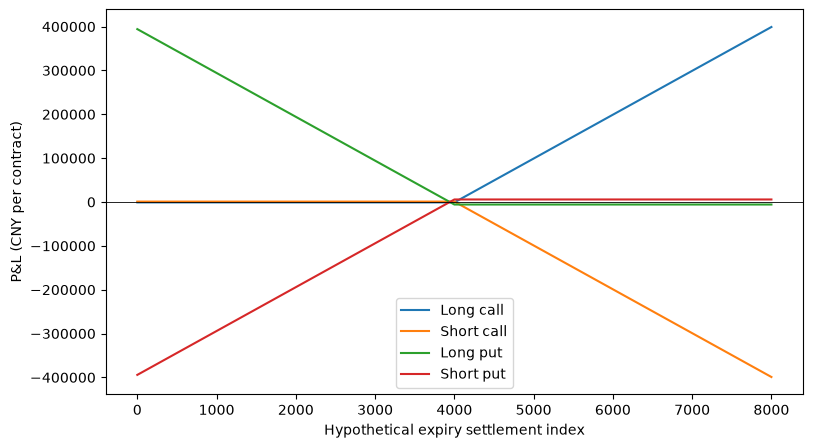

,Position,Break-even,Maximum loss (CNY),Maximum gain (CNY)
0,Long call,4009.2,-920.0,unbounded
1,Short call,4009.2,unbounded,920.0
2,Long put,3942.4,-5760.0,394240.0
3,Short put,3942.4,-394240.0,5760.0


In [3]:
x = np.linspace(0, 2 * K, 401)
fig, ax = plt.subplots(figsize=(9, 5))
for label, values in zip(("Long call", "Short call", "Long put", "Short put"), payoffs(x)):
    ax.plot(x, values, label=label)
ax.axhline(0, color="black", linewidth=0.6)
ax.set(xlabel="Hypothetical expiry settlement index", ylabel="P&L (CNY per contract)")
ax.legend()
plt.show()
summary = {"call_break_even": K + c, "put_break_even": K - p,
           "long_call_max_loss": -c * multiplier, "short_call_max_gain": c * multiplier,
           "long_call_max_gain": "unbounded", "short_call_max_loss": "unbounded",
           "long_put_max_loss": -p * multiplier, "short_put_max_gain": p * multiplier,
           "long_put_max_gain": (K - p) * multiplier, "short_put_max_loss": -(K - p) * multiplier,
           "call_premium": c, "put_premium": p, "strike": K, "multiplier": multiplier,
           "index_close": index_close, "classification": manifest.experiment_id}
display(pd.DataFrame([
    ["Long call", K + c, summary["long_call_max_loss"], "unbounded"],
    ["Short call", K + c, "unbounded", summary["short_call_max_gain"]],
    ["Long put", K - p, summary["long_put_max_loss"], summary["long_put_max_gain"]],
    ["Short put", K - p, summary["short_put_max_loss"], summary["short_put_max_gain"]],
], columns=["Position", "Break-even", "Maximum loss (CNY)", "Maximum gain (CNY)"]))

## 5. Checks

The manifest model validates its six fields; the loaded revision pins must match its three pin fields.

In [4]:
assert set(Manifest.model_fields) == {"inputs", "economic_conventions", "vectorbt_version", "seed", "window", "experiment_id"}
assert set(manifest.inputs) == set(data)
for name, revision in data.items():
    assert revision.pin == manifest.inputs[name].model_copy(update={"calendar_unverified": None}), f"revision pin mismatch: {name}"
    print(f"{name}: revision_id, window and content_digest match")
lc, sc, lp, sp = payoffs(np.array([0., K - 100, K, K + 100]))
assert all(values.shape == x.shape for values in payoffs(x))
assert np.allclose(lc, -sc) and np.allclose(lp, -sp)
assert lc[1] == lc[2] == -c * multiplier and lc[3] > lc[2]
assert lp[3] == lp[2] == -p * multiplier and lp[1] > lp[2]
assert np.isclose(lc[3], (100 - c) * multiplier)
assert np.isclose(lp[1], (100 - p) * multiplier)
assert lp[0] == (K - p) * multiplier
assert np.isclose(payoffs(K + c)[0], 0) and np.isclose(payoffs(K - p)[2], 0)
print("Checks passed: curve shape, ITM/OTM settlement, multiplier and break-even.")
print(json.dumps(summary, sort_keys=True))

option_contracts: revision_id, window and content_digest match
option_bars: revision_id, window and content_digest match
index_bars: revision_id, window and content_digest match
Checks passed: curve shape, ITM/OTM settlement, multiplier and break-even.
{"call_break_even": 4009.2, "call_premium": 9.2, "classification": "replication_diagnostic", "index_close": 3984.84, "long_call_max_gain": "unbounded", "long_call_max_loss": -919.9999999999999, "long_put_max_gain": 394240.0, "long_put_max_loss": -5760.0, "multiplier": 100.0, "put_break_even": 3942.4, "put_premium": 57.6, "short_call_max_gain": 919.9999999999999, "short_call_max_loss": "unbounded", "short_put_max_gain": 5760.0, "short_put_max_loss": -394240.0, "strike": 4000.0}


## 6. Assumptions & boundaries

The observed index close is context, **not** the official expiration settlement. Hypothetical settlement values are nonnegative. No fees, discounting or early exercise are included. The premium is indicative and does not establish an executable price or strategy performance.